In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [29]:
# import the dataset
maternity = pd.read_csv("clean_data.csv")
maternity.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1164 entries, 0 to 1163
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Unnamed: 0              1164 non-null   int64  
 1   Age                     1164 non-null   int64  
 2   Systolic BP             1164 non-null   float64
 3   Diastolic               1164 non-null   float64
 4   BS                      1164 non-null   float64
 5   Body Temp               1164 non-null   int64  
 6   BMI                     1164 non-null   float64
 7   Previous Complications  1164 non-null   float64
 8   Preexisting Diabetes    1164 non-null   float64
 9   Gestational Diabetes    1164 non-null   int64  
 10  Mental Health           1164 non-null   int64  
 11  Heart Rate              1164 non-null   float64
 12  Risk Level              1164 non-null   object 
dtypes: float64(7), int64(5), object(1)
memory usage: 118.3+ KB


In [30]:
# drop the unnamed column
maternity.drop(columns=["Unnamed: 0"], inplace=True)

In [31]:
maternity.head()

,Age,Systolic BP,Diastolic,BS,Body Temp,BMI,Previous Complications,Preexisting Diabetes,Gestational Diabetes,Mental Health,Heart Rate,Risk Level
0,22,90.0,60.0,9.0,100,18.0,1.0,1.0,0,1,80.0,High
1,22,110.0,70.0,7.1,98,20.4,0.0,0.0,0,0,74.0,Low
2,27,110.0,70.0,7.5,98,23.0,1.0,0.0,0,0,72.0,Low
3,20,100.0,70.0,7.2,98,21.2,0.0,0.0,0,0,74.0,Low
4,20,90.0,60.0,7.5,98,19.7,0.0,0.0,0,0,74.0,Low


# Exploratory Data Analysis

In [32]:
# summary statistics
summary = maternity.describe()
summary.T

,count,mean,std,min,25%,50%,75%,max
Age,1164.0,27.510309,9.258626,10.0,21.000,25.0,32.000,65.0
Systolic BP,1164.0,116.896907,18.734274,70.0,100.000,120.0,130.000,200.0
Diastolic,1164.0,77.295533,14.293880,40.0,65.000,80.0,90.000,140.0
BS,1164.0,7.525576,3.061182,3.0,6.000,6.9,7.925,19.0
Body Temp,1164.0,98.383162,1.073847,97.0,98.000,98.0,98.000,103.0
BMI,1164.0,23.361082,3.828619,15.0,20.975,23.0,25.025,37.0
Previous Complications,1164.0,0.177835,0.382538,0.0,0.000,0.0,0.000,1.0
Preexisting Diabetes,1164.0,0.289519,0.453734,0.0,0.000,0.0,1.000,1.0
Gestational Diabetes,1164.0,0.117698,0.322388,0.0,0.000,0.0,0.000,1.0
Mental Health,1164.0,0.334192,0.471910,0.0,0.000,0.0,1.000,1.0


In [33]:
maternity["Risk Level"].value_counts()

Risk Level
Low     700
High    464
Name: count, dtype: int64

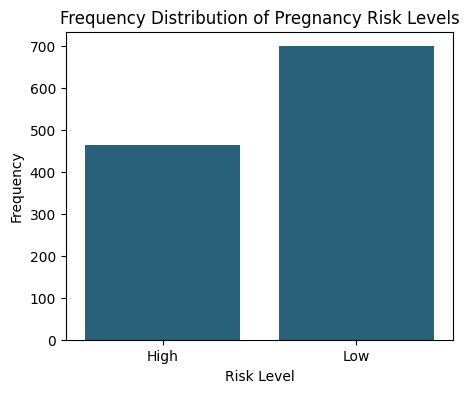

In [34]:
# frequency distribution of target variable
fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(x=maternity["Risk Level"], color="#1c6488", ax=ax)
plt.ylabel("Frequency")
plt.title("Frequency Distribution of Pregnancy Risk Levels")
plt.show()

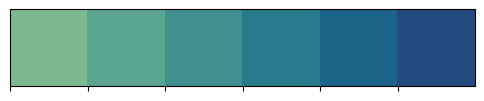

Color 1: #7dba91
Color 2: #59a590
Color 3: #40908e
Color 4: #287a8c
Color 5: #1c6488
Color 6: #254b7f


In [35]:
from matplotlib.colors import to_hex
colors = sns.color_palette("crest", 6)
sns.palplot(colors)
plt.show()
for i, c in enumerate(colors):
    print(f"Color {i+1}: {to_hex(c)}")

In [36]:
# specify categorical and numerical variables
cat_cols = ["Previous Complications", "Preexisting Diabetes", "Gestational Diabetes", "Mental Health"]
num_cols = [col for col in maternity.columns if col != "Risk Level" and col not in cat_cols]

print(num_cols)

['Age', 'Systolic BP', 'Diastolic', 'BS', 'Body Temp', 'BMI', 'Heart Rate']


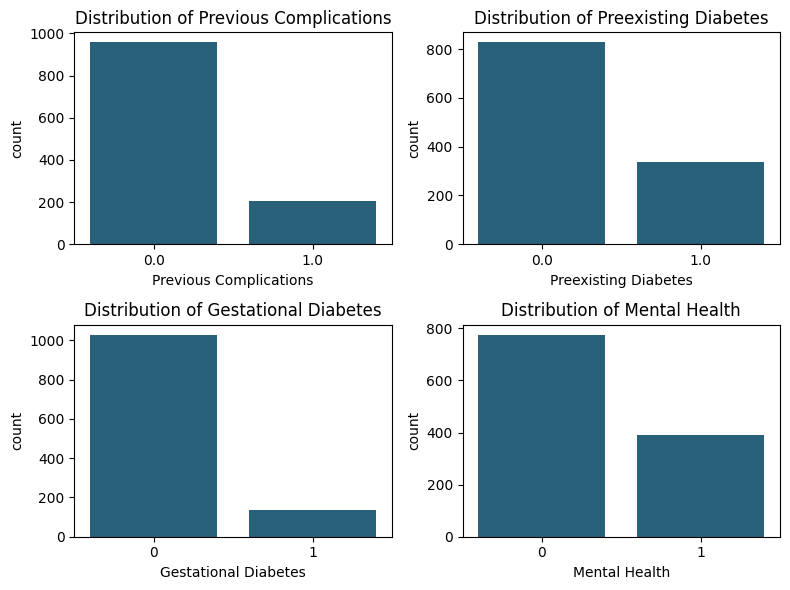

In [37]:
# frequency distribution of the categorical columns

# create a figure and a 2x2 grid of subplots
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(8, 6))

# flatten 2D axes to 1D list
axes = axes.flatten()

# plot
for i, col in enumerate(cat_cols):
    ax=axes[i]
    sns.countplot(data=maternity, x=col, ax=ax, color="#1c6488")
    ax.set_title(f"Distribution of {col}")
    #ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()


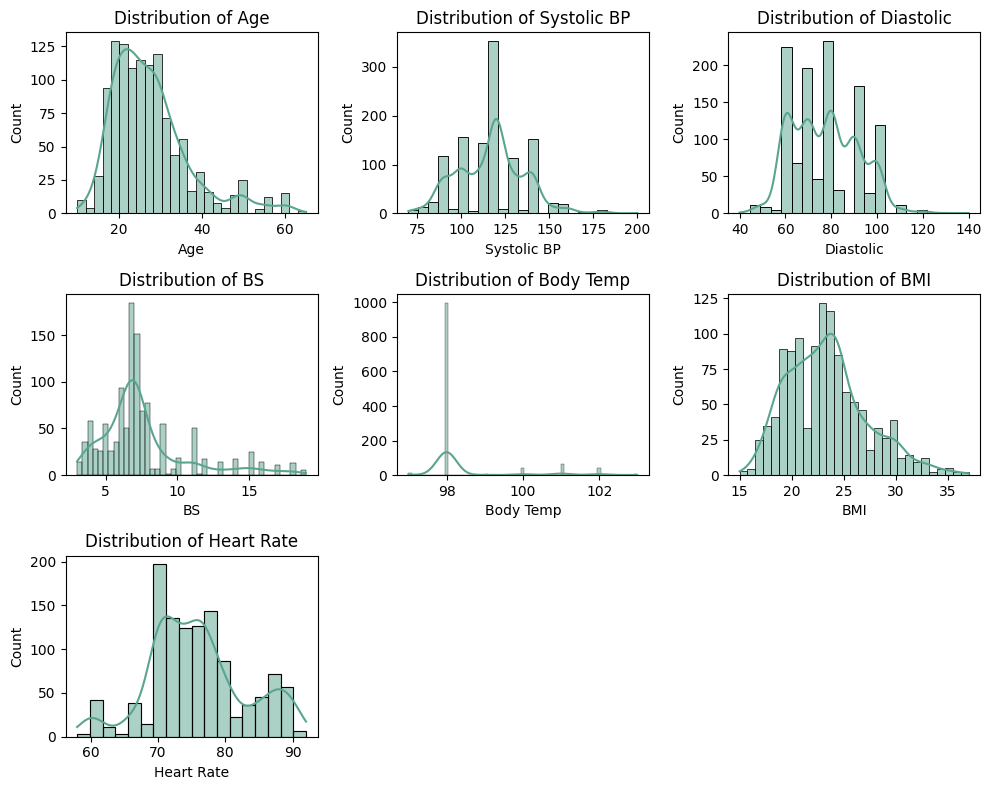

In [38]:
# frequency distribution of the numerical variables

# create a figure and a 3x3 subplot grid
fig, axes = plt.subplots(ncols=3, nrows=3, figsize=(10, 8))
# flatten axes
axes = axes.flatten()

# plot
for i, col in enumerate(num_cols):
    ax = axes[i]
    sns.histplot(data=maternity, x=col, ax=ax, color="#59a590", kde=True)
    ax.set_title(f"Distribution of {col}")

# remove the unused subplots
for j in range(len(num_cols), len(axes)):
    fig.delaxes(axes[j])

    
plt.tight_layout()
plt.show()

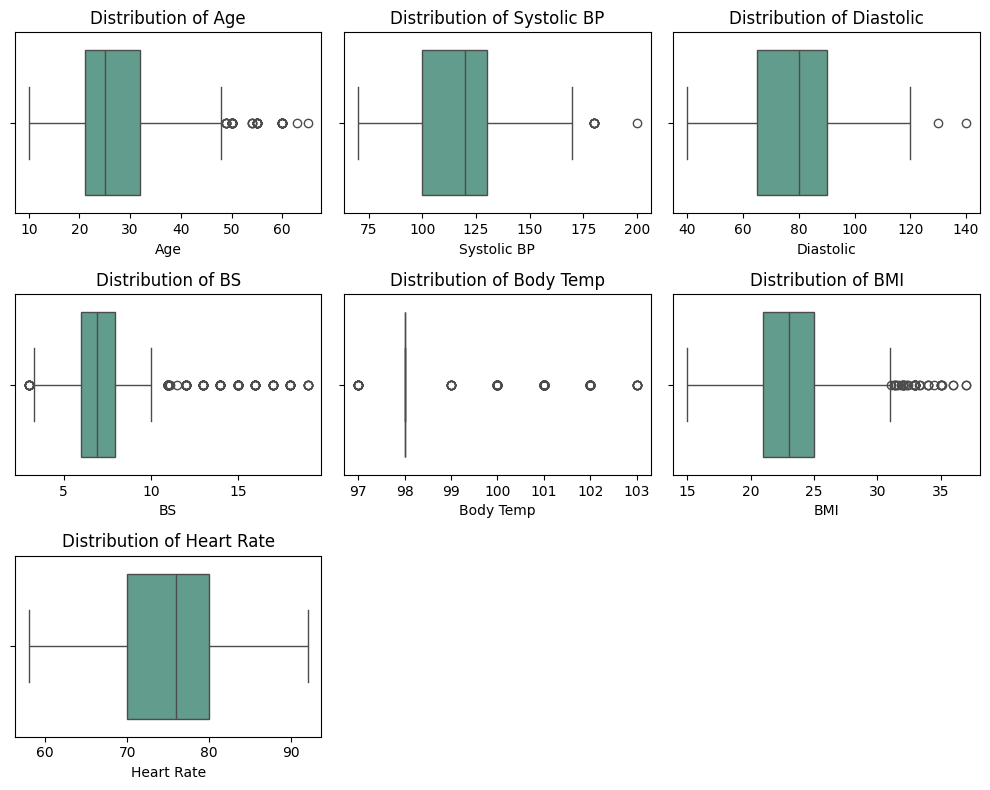

In [39]:
# create a figure and a 3x3 subplot grid
fig, axes = plt.subplots(ncols=3, nrows=3, figsize=(10, 8))
# flatten axes
axes = axes.flatten()

# plot
for i, col in enumerate(num_cols):
    ax = axes[i]
    sns.boxplot(data=maternity, x=col, ax=ax, color="#59a590", orient='h', fill=True)
    ax.set_title(f"Distribution of {col}")

# remove the unused subplots
for j in range(len(num_cols), len(axes)):
    fig.delaxes(axes[j])

    
plt.tight_layout()
plt.show()

# Categorical Variables - Bivariate Analysis


In [40]:
# crosstabs to compare categorical variables with the target variable
pc = pd.crosstab(maternity["Risk Level"], maternity["Previous Complications"], normalize="index")
pdi = pd.crosstab(maternity["Risk Level"], maternity["Preexisting Diabetes"], normalize="index")
gd = pd.crosstab(maternity["Risk Level"], maternity["Gestational Diabetes"], normalize="index")
mh = pd.crosstab(maternity["Risk Level"], maternity["Mental Health"], normalize="index")

# add label to each crosstab
pc["feature"] = "Previous Complications"
pdi["feature"] = "Preexisting Diabetes"
gd["feature"] = "Gestational Diabetes"
mh["feature"] = "Mental Health"

# combine all
combined_ct = pd.concat([pc, pdi, gd, mh], axis=0)
combined_ct

,0.0,1.0,feature
Risk Level,,,
High,0.566810,0.433190,Previous Complications
Low,0.991429,0.008571,Previous Complications
High,0.325431,0.674569,Preexisting Diabetes
Low,0.965714,0.034286,Preexisting Diabetes
High,0.704741,0.295259,Gestational Diabetes
Low,1.000000,0.000000,Gestational Diabetes
High,0.299569,0.700431,Mental Health
Low,0.908571,0.091429,Mental Health


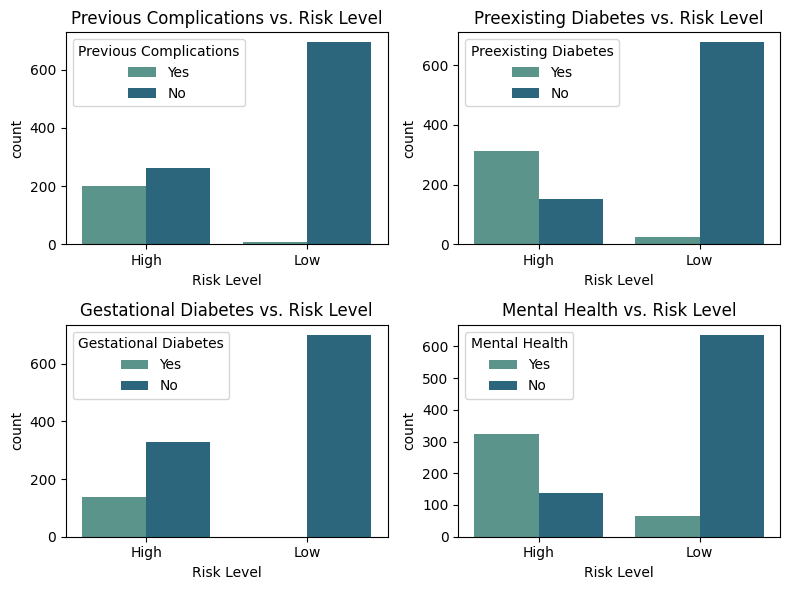

In [41]:
# compare the categorical features with the target variables
# frequency distribution of the categorical columns

# change 0,1 to No and Yes
for col in cat_cols:
    maternity[col] = maternity[col].map({0:"No", 1:"Yes"})

# create a figure and a 2x2 grid of subplots
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(8, 6))

# flatten 2D axes to 1D list
axes = axes.flatten()

# plot
for i, col in enumerate(cat_cols):
    ax=axes[i]
    sns.countplot(data=maternity, x="Risk Level", ax=ax, hue=col, palette="crest", hue_order=["Yes", "No"])
    ax.set_title(f"{col} vs. Risk Level")
    #ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()


# Categorical Variable - Multivariate Analysis

In [42]:
# filter the dataset to include only those with high-risk pregnancies
maternity_high = maternity[maternity["Risk Level"] == "High"]
maternity_high.head()

,Age,Systolic BP,Diastolic,BS,Body Temp,BMI,Previous Complications,Preexisting Diabetes,Gestational Diabetes,Mental Health,Heart Rate,Risk Level
0,22,90.0,60.0,9.0,100,18.0,Yes,Yes,No,Yes,80.0,High
6,20,110.0,70.0,9.0,102,17.6,No,Yes,No,No,78.0,High
9,26,110.0,70.0,12.0,100,30.2,Yes,Yes,Yes,Yes,80.0,High
11,22,120.0,70.0,9.9,101,30.0,Yes,No,Yes,No,84.0,High
19,44,140.0,100.0,14.0,98,25.3,No,Yes,No,Yes,88.0,High


In [43]:
from itertools import combinations

cat_cols = [cols for cols in cat_cols if cols != "Gestational Diabetes"]
for col1, col2 in combinations(cat_cols, 2):
    print(f"\nCrosstab: {col1} vs {col2}")
    display(pd.crosstab(maternity_high[col1], maternity_high[col2], normalize="index"))


Crosstab: Previous Complications vs Preexisting Diabetes


Preexisting Diabetes,No,Yes
Previous Complications,,
No,0.311787,0.688213
Yes,0.343284,0.656716



Crosstab: Previous Complications vs Mental Health


Mental Health,No,Yes
Previous Complications,,
No,0.376426,0.623574
Yes,0.199005,0.800995



Crosstab: Preexisting Diabetes vs Mental Health


Mental Health,No,Yes
Preexisting Diabetes,,
No,0.264901,0.735099
Yes,0.316294,0.683706


In [44]:
bi_var = maternity_high.groupby([col1, col2]).size().reset_index(name='counts')
bi_var["total"] = bi_var.groupby(col1)["counts"].transform("sum")
bi_var["proportion"] = bi_var["counts"] / bi_var["total"]
bi_var

,Preexisting Diabetes,Mental Health,counts,total,proportion
0,No,No,40,151,0.264901
1,No,Yes,111,151,0.735099
2,Yes,No,99,313,0.316294
3,Yes,Yes,214,313,0.683706


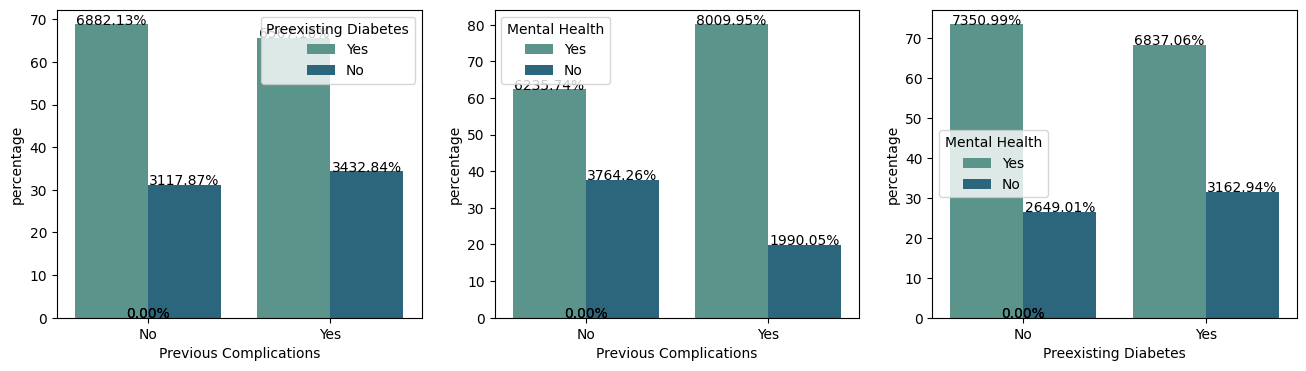

In [45]:
# create a figure and a subplot grid
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16, 4))
# flatten the axes to a 1D array
axes = axes.flatten()

# plot
for i, (col1, col2) in enumerate(combinations(cat_cols, 2)):
    # calculate the size for each group
    bi_var = maternity_high.groupby([col1, col2]).size().reset_index(name='counts')
    # calculate total counts for the first group
    bi_var["total"] = bi_var.groupby(col1)["counts"].transform("sum")
    # calculate proportion for each category
    bi_var["percentage"] = bi_var["counts"] / bi_var["total"] * 100
    # plot normalized countplots
    bar = sns.barplot(data=bi_var, x=col1, y="percentage", ax=axes[i], hue=col2, palette="crest", hue_order=["Yes", "No"])
    
    # add percentage labels on the bars
    for p in bar.patches:
        height = p.get_height()
        bar.text(p.get_x() + p.get_width()/2, height+0.01, f'{height:.2%}', ha="center")
        
plt.show()

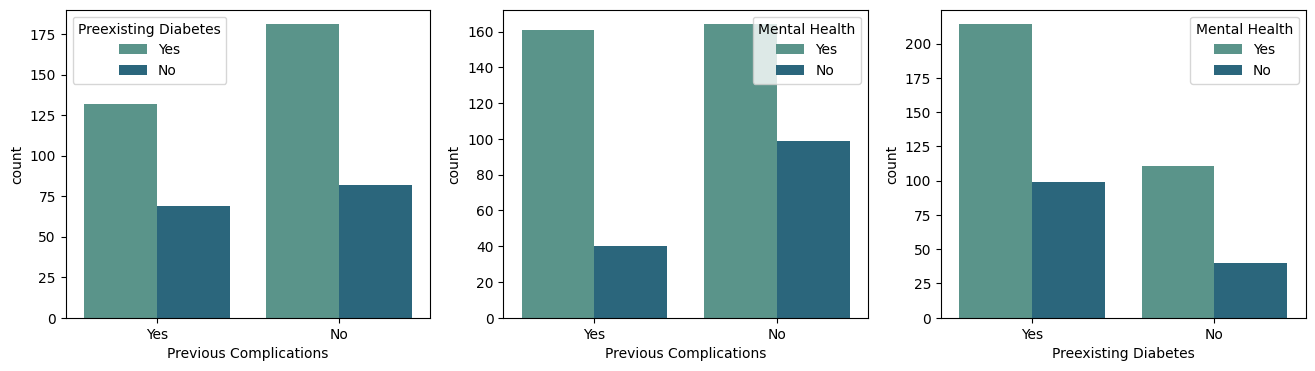

In [46]:
# create a figure and a subplot grid
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16, 4))
# flatten the axes to a 1D array
axes = axes.flatten()

# plot
for i, (col1, col2) in enumerate(combinations(cat_cols, 2)):
    sns.countplot(data=maternity_high, x=col1, ax=axes[i], hue=col2, palette="crest", hue_order=["Yes", "No"])

# Numerical Variables: Bivariate Analysis

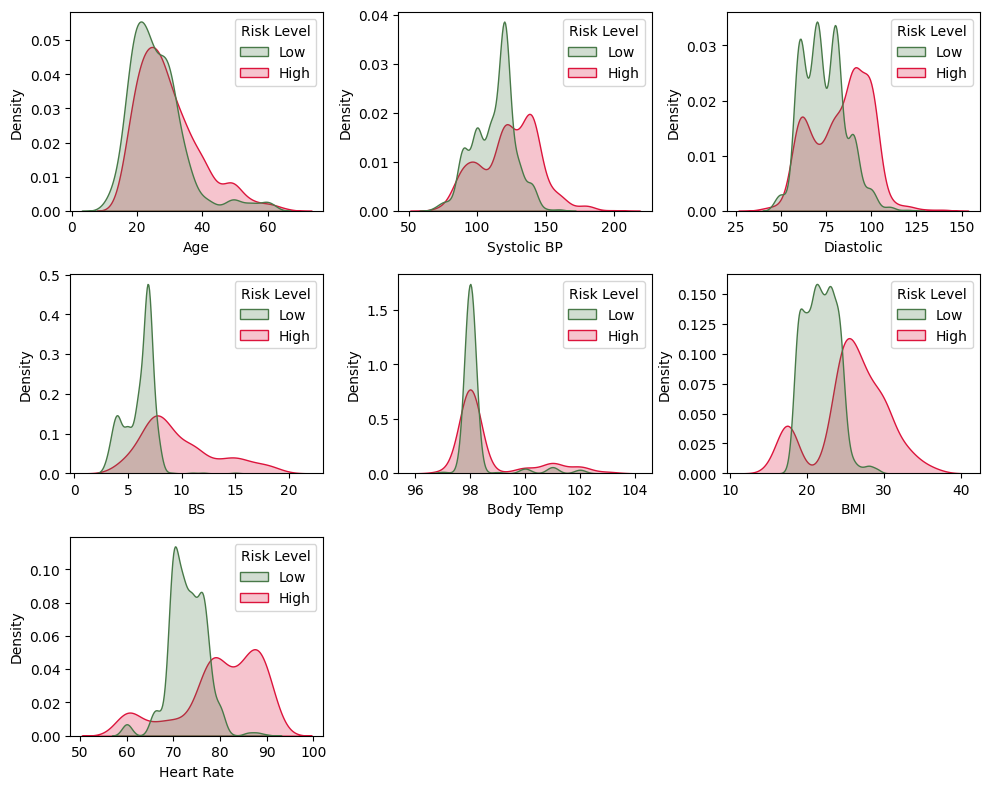

In [47]:
# create a figure and a 3x3 subplot
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(10, 8))
# flatten axes into a 1D array
axes = axes.flatten()

# plot
for i, col in enumerate(num_cols):
    ax = axes[i]
    sns.kdeplot(data=maternity, x=col, hue="Risk Level", hue_order=["Low", "High"], ax=ax, fill=True, palette={"Low": "#487948", "High": "#DC143C"}, common_norm=False)
    plt.xlabel(f"{col}")
    plt.title(f"{col} Distribution")

# remove unused axes
for j in range(len(num_cols), len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

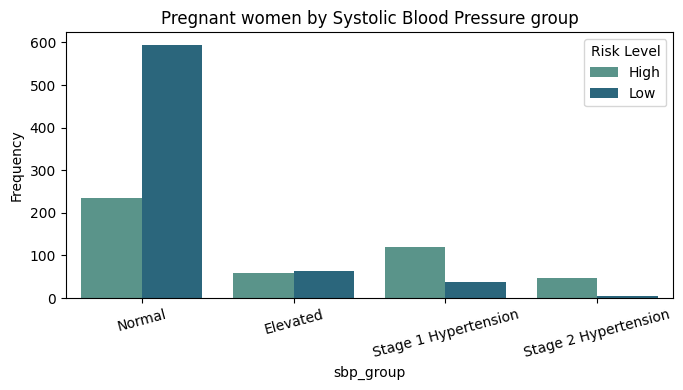

In [48]:
bins = [0, 120, 130, 140, float("inf")]
labels = ["Normal", "Elevated", "Stage 1 Hypertension", "Stage 2 Hypertension"]
maternity["sbp_group"] = pd.cut(maternity["Systolic BP"], bins=bins, labels=labels, right=True)

# plot as a countplot
plt.figure(figsize=(7,4))
sns.countplot(data=maternity, x="sbp_group", order=labels, hue="Risk Level", palette="crest")
plt.title("Pregnant women by Systolic Blood Pressure group")
plt.ylabel("Frequency")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

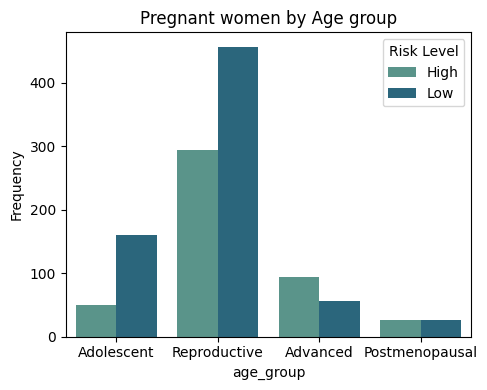

In [49]:
bins = [0, 19, 34, 49, 65]
labels = ["Adolescent", "Reproductive", "Advanced", "Postmenopausal"]
maternity["age_group"] = pd.cut(maternity["Age"], bins=bins, labels=labels, right=True)

# plot as a countplot
plt.figure(figsize=(5,4))
sns.countplot(data=maternity, x="age_group", order=labels, hue="Risk Level", palette="crest")
plt.title("Pregnant women by Age group")
plt.ylabel("Frequency")
#plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

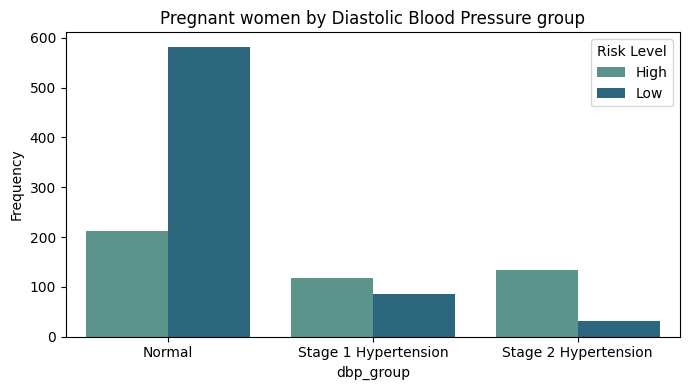

In [50]:
bins = [0, 80, 90, float("inf")]
labels = ["Normal", "Stage 1 Hypertension", "Stage 2 Hypertension"]
maternity["dbp_group"] = pd.cut(maternity["Diastolic"], bins=bins, labels=labels, right=True)

# plot as a countplot
plt.figure(figsize=(7,4))
sns.countplot(data=maternity, x="dbp_group", order=labels, hue="Risk Level", palette="crest")
plt.title("Pregnant women by Diastolic Blood Pressure group")
plt.ylabel("Frequency")
#plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

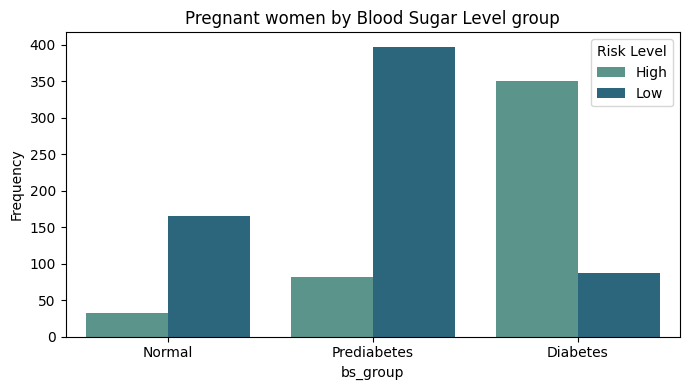

In [51]:
bins = [3.8, 5.6, 7.0, float("inf")]
labels = ["Normal", "Prediabetes", "Diabetes"]
maternity["bs_group"] = pd.cut(maternity["BS"], bins=bins, labels=labels, right=True)

# plot as a countplot
plt.figure(figsize=(7,4))
sns.countplot(data=maternity, x="bs_group", order=labels, hue="Risk Level", palette="crest")
plt.title("Pregnant women by Blood Sugar Level group")
plt.ylabel("Frequency")
#plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

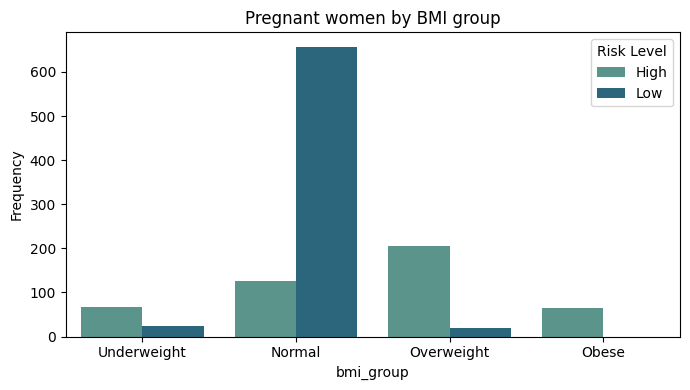

In [52]:
bins = [0, 18.5, 25, 30, float("inf")]
labels = ["Underweight", "Normal", "Overweight", "Obese"]
maternity["bmi_group"] = pd.cut(maternity["BMI"], bins=bins, labels=labels, right=True)

# plot as a countplot
plt.figure(figsize=(7,4))
sns.countplot(data=maternity, x="bmi_group", order=labels, hue="Risk Level", palette="crest")
plt.title("Pregnant women by BMI group")
plt.ylabel("Frequency")
#plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

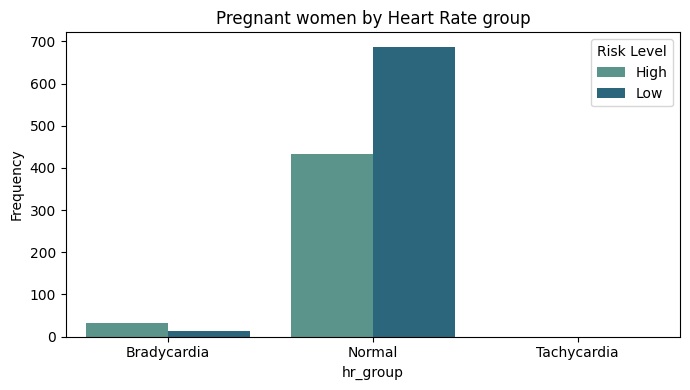

In [53]:
bins = [0, 60, 101, float("inf")]
labels = ["Bradycardia", "Normal", "Tachycardia"]
maternity["hr_group"] = pd.cut(maternity["Heart Rate"], bins=bins, labels=labels, right=True)

# plot as a countplot
plt.figure(figsize=(7,4))
sns.countplot(data=maternity, x="hr_group", order=labels, hue="Risk Level", palette="crest")
plt.title("Pregnant women by Heart Rate group")
plt.ylabel("Frequency")
#plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

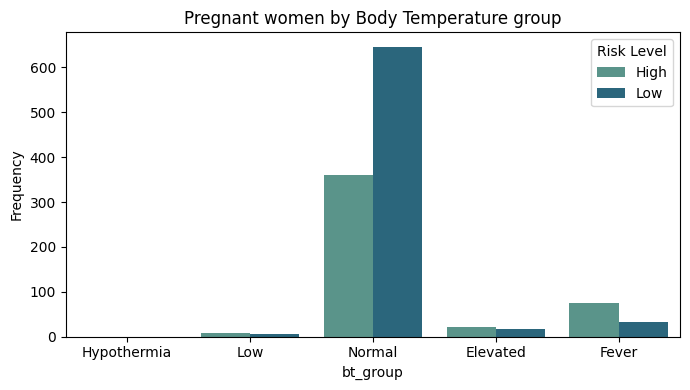

In [54]:
bins = [0, 95, 97, 99.5, 100.4, float("inf")]
labels = ["Hypothermia", "Low", "Normal", "Elevated", "Fever"]
maternity["bt_group"] = pd.cut(maternity["Body Temp"], bins=bins, labels=labels, right=True)

# plot as a countplot
plt.figure(figsize=(7,4))
sns.countplot(data=maternity, x="bt_group", order=labels, hue="Risk Level", palette="crest")
plt.title("Pregnant women by Body Temperature group")
plt.ylabel("Frequency")
#plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [55]:
maternity.head()

,Age,Systolic BP,Diastolic,BS,Body Temp,BMI,Previous Complications,Preexisting Diabetes,Gestational Diabetes,Mental Health,Heart Rate,Risk Level,sbp_group,age_group,dbp_group,bs_group,bmi_group,hr_group,bt_group
0,22,90.0,60.0,9.0,100,18.0,Yes,Yes,No,Yes,80.0,High,Normal,Reproductive,Normal,Diabetes,Underweight,Normal,Elevated
1,22,110.0,70.0,7.1,98,20.4,No,No,No,No,74.0,Low,Normal,Reproductive,Normal,Diabetes,Normal,Normal,Normal
2,27,110.0,70.0,7.5,98,23.0,Yes,No,No,No,72.0,Low,Normal,Reproductive,Normal,Diabetes,Normal,Normal,Normal
3,20,100.0,70.0,7.2,98,21.2,No,No,No,No,74.0,Low,Normal,Reproductive,Normal,Diabetes,Normal,Normal,Normal
4,20,90.0,60.0,7.5,98,19.7,No,No,No,No,74.0,Low,Normal,Reproductive,Normal,Diabetes,Normal,Normal,Normal


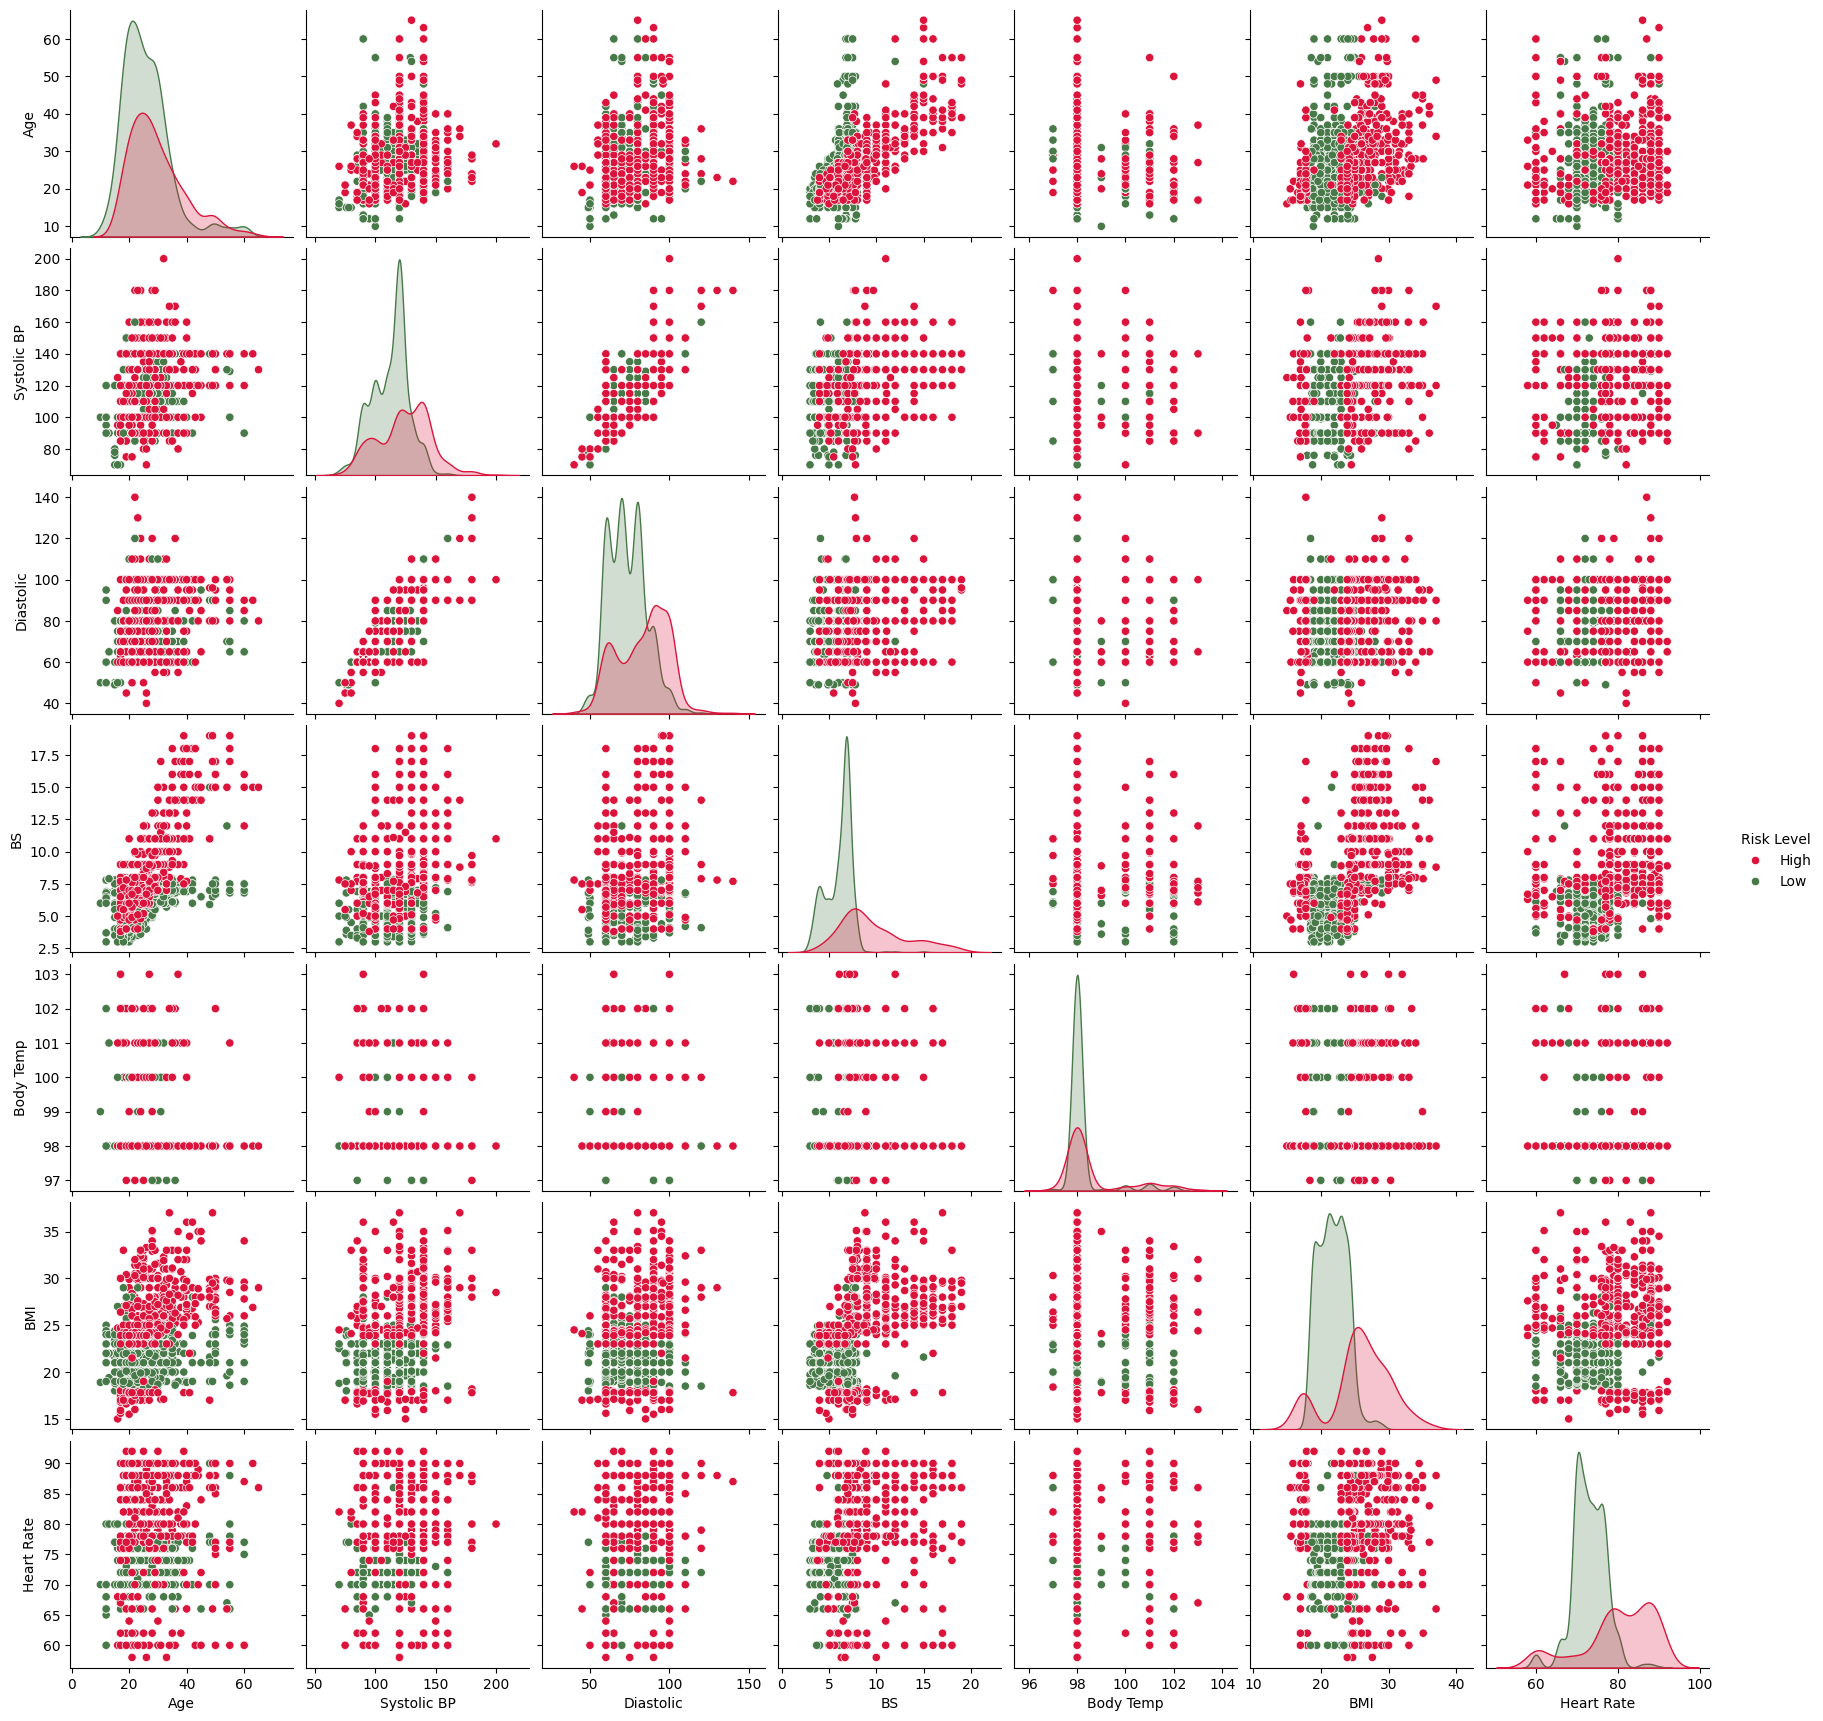

In [56]:
sns.pairplot(data=maternity, hue="Risk Level", palette={"Low": "#487948", "High": "#DC143C"})

In [63]:
maternity.groupby("Risk Level")[["Age", "BS"]].corr().iloc[0::2, 1]

Risk Level     
High        Age    0.794506
Low         Age    0.409459
Name: BS, dtype: float64

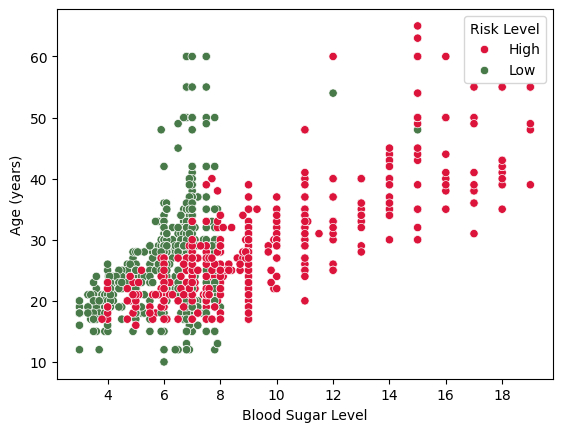

In [60]:
sns.scatterplot(data=maternity, x="BS", y="Age", hue="Risk Level", palette={"Low": "#487948", "High": "#DC143C"})
plt.xlabel("Blood Sugar Level")
plt.ylabel("Age (years)")
plt.show()